# Week 5: Detailed Error Analysis of Hough Transform

## Objective

The previous experimental comparison indicated that the Hough Transform
produced the highest angular error among the three orientation estimation
methods.

Therefore, Week 5 focuses specifically on investigating its performance
and identifying the factors that may contribute to inaccurate orientation
estimation.

### Tasks

1. Analyse the angular error of Hough Transform for each vehicle class.
2. Identify the vehicle class with the highest mean angular error.
3. Examine the individual samples with the largest prediction errors.
4. Study the relationship between vehicle orientation and angular error.
5. Investigate possible reasons for the poor performance of Hough Transform.

The analysis uses the same 100-vehicle evaluation dataset from Week 3.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

BASE_DIR = "/content/drive/MyDrive/ECE501_DRASHTI"

WEEK3_CSV = os.path.join(
    BASE_DIR,
    "Week3_Results",
    "week3_100_image_error_table.csv"
)

WEEK5_DIR = os.path.join(BASE_DIR, "Week5_Results")

GRAPHS_DIR = os.path.join(WEEK5_DIR, "graphs")
TABLES_DIR = os.path.join(WEEK5_DIR, "tables")

os.makedirs(GRAPHS_DIR, exist_ok=True)
os.makedirs(TABLES_DIR, exist_ok=True)

print("Week 5 folders created successfully!")
print("Graphs:", GRAPHS_DIR)
print("Tables:", TABLES_DIR)

Mounted at /content/drive
Week 5 folders created successfully!
Graphs: /content/drive/MyDrive/ECE501_DRASHTI/Week5_Results/graphs
Tables: /content/drive/MyDrive/ECE501_DRASHTI/Week5_Results/tables


## 1. Loading the Experimental Results

The analysis is based on the experimental results obtained from the
100 vehicle samples evaluated in Week 3.

For each sample, the dataset contains the ground-truth orientation,
Hough Transform estimated orientation, and the corresponding angular error.

Only the Hough Transform results are considered in this analysis,
as the objective is to investigate its comparatively high error.

In [2]:
df = pd.read_csv(WEEK3_CSV)

print("Total samples:", len(df))
print("\nAvailable columns:")
print(df.columns.tolist())

required_columns = [
    "Vehicle_ID",
    "Vehicle_Class",
    "Ground_Truth_Orientation_deg",
    "Hough_Estimated_Orientation_deg"
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

df["Ground_Truth_Orientation_deg"] = pd.to_numeric(
    df["Ground_Truth_Orientation_deg"],
    errors="coerce"
)

df["Hough_Estimated_Orientation_deg"] = pd.to_numeric(
    df["Hough_Estimated_Orientation_deg"],
    errors="coerce"
)

# Angular error for the project's 0–90 degree representation
df["Hough_Angular_Error_deg"] = abs(
    df["Ground_Truth_Orientation_deg"]
    - df["Hough_Estimated_Orientation_deg"]
)

valid_df = df.dropna(
    subset=[
        "Ground_Truth_Orientation_deg",
        "Hough_Estimated_Orientation_deg"
    ]
).copy()

valid_df["Vehicle_Class"] = (
    valid_df["Vehicle_Class"]
    .fillna("Unknown")
    .astype(str)
)

print("\nValid Hough predictions:", len(valid_df))
print("Failed/Missing predictions:", len(df) - len(valid_df))

if valid_df.empty:
    raise ValueError("No valid Hough predictions found.")

print("\nMean Angular Error:",
      round(valid_df["Hough_Angular_Error_deg"].mean(), 2))

print("Median Angular Error:",
      round(valid_df["Hough_Angular_Error_deg"].median(), 2))

print("Maximum Angular Error:",
      round(valid_df["Hough_Angular_Error_deg"].max(), 2))

Total samples: 100

Available columns:
['Vehicle_ID', 'Image_ID', 'Vehicle_Number', 'Class_ID', 'Vehicle_Class', 'Difficulty', 'Ground_Truth_Heading_deg', 'Ground_Truth_Orientation_deg', 'PCA_Estimated_Orientation_deg', 'PCA_Angular_Error_deg', 'Hough_Estimated_Orientation_deg', 'Hough_Angular_Error_deg', 'Contour_Estimated_Orientation_deg', 'Contour_Angular_Error_deg']

Valid Hough predictions: 98
Failed/Missing predictions: 2

Mean Angular Error: 12.46
Median Angular Error: 4.18
Maximum Angular Error: 82.39


## 2. Class-Wise Angular Error Analysis

To determine whether certain vehicle types are more difficult for
the Hough Transform, the angular errors are grouped according to
vehicle class.

For each class, the following statistics are calculated:

- Number of vehicle samples
- Mean angular error
- Median angular error
- Maximum angular error
- Standard deviation of angular error

The classes are ranked according to their mean angular error.

This comparison helps identify vehicle categories where the Hough
Transform produces relatively inaccurate orientation estimates.

In [3]:
class_stats = valid_df.groupby("Vehicle_Class").agg(
    Sample_Count=("Hough_Angular_Error_deg", "count"),
    Mean_Error_deg=("Hough_Angular_Error_deg", "mean"),
    Median_Error_deg=("Hough_Angular_Error_deg", "median"),
    Maximum_Error_deg=("Hough_Angular_Error_deg", "max"),
    Standard_Deviation_deg=("Hough_Angular_Error_deg", "std")
).reset_index()

class_stats["Standard_Deviation_deg"] = (
    class_stats["Standard_Deviation_deg"].fillna(0)
)

class_stats = class_stats.sort_values(
    "Mean_Error_deg",
    ascending=False
)

class_stats.to_csv(
    os.path.join(
        TABLES_DIR,
        "01_hough_classwise_error_analysis.csv"
    ),
    index=False
)

display(class_stats)

worst_class = class_stats.iloc[0]

print("\nCLASS WITH HIGHEST MEAN HOUGH ERROR")
print("------------------------------------")
print("Vehicle Class:", worst_class["Vehicle_Class"])
print("Mean Error:", round(worst_class["Mean_Error_deg"], 2))
print("Sample Count:", int(worst_class["Sample_Count"]))

if worst_class["Sample_Count"] < 5:
    print(
        "CAUTION: Fewer than 5 samples in this class."
        " Interpret this ranking carefully."
    )

,Vehicle_Class,Sample_Count,Mean_Error_deg,Median_Error_deg,Maximum_Error_deg,Standard_Deviation_deg
3,Container,2,49.130000,49.130,77.16,39.640406
0,Auto3WCargo,3,38.583333,19.980,81.49,37.267399
9,Trailer,3,32.866667,8.910,82.39,42.896019
5,PickUp,4,20.717500,8.060,65.27,30.115038
10,Truck,5,17.502000,4.930,61.81,25.334291
1,AutoRicksaw,8,13.968750,8.070,63.49,20.596637
6,SUV,34,12.973235,4.055,79.96,21.044625
7,Sedan,7,7.032857,3.800,19.86,7.709197
4,MotorCycle,29,4.543448,2.790,18.35,4.095297
8,Tanker,1,3.270000,3.270,3.27,0.000000



CLASS WITH HIGHEST MEAN HOUGH ERROR
------------------------------------
Vehicle Class: Container
Mean Error: 49.13
Sample Count: 2
CAUTION: Fewer than 5 samples in this class. Interpret this ranking carefully.


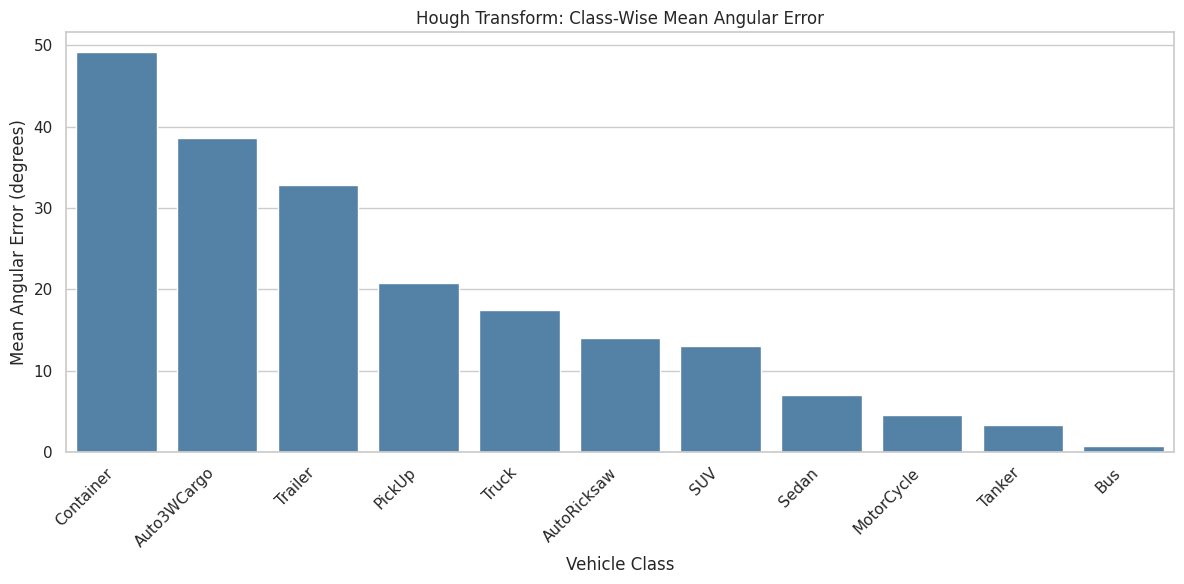

In [4]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=class_stats,
    x="Vehicle_Class",
    y="Mean_Error_deg",
    color="steelblue"
)

plt.xticks(rotation=45, ha="right")

plt.xlabel("Vehicle Class")
plt.ylabel("Mean Angular Error (degrees)")

plt.title(
    "Hough Transform: Class-Wise Mean Angular Error"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPHS_DIR,
        "01_hough_classwise_mean_error.png"
    ),
    dpi=300
)

plt.show()

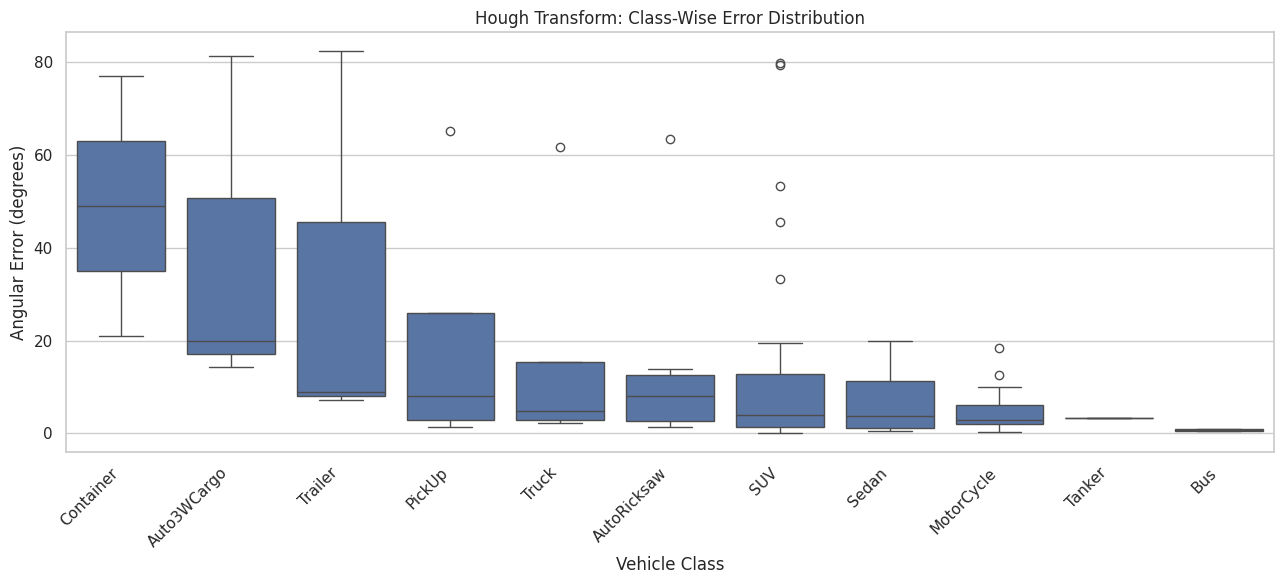

In [5]:
plt.figure(figsize=(13, 6))

sns.boxplot(
    data=valid_df,
    x="Vehicle_Class",
    y="Hough_Angular_Error_deg",
    order=class_stats["Vehicle_Class"]
)

plt.xticks(rotation=45, ha="right")

plt.xlabel("Vehicle Class")
plt.ylabel("Angular Error (degrees)")

plt.title(
    "Hough Transform: Class-Wise Error Distribution"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPHS_DIR,
        "02_hough_classwise_error_boxplot.png"
    ),
    dpi=300
)

plt.show()

### Interpretation

The class-wise mean angular error graph compares the average
Hough Transform error across different vehicle categories.

The error distribution plot provides additional information
about the variation in errors within each class.

A class with a high mean error may indicate that its vehicle
geometry or visible edge patterns are difficult for the Hough
Transform to interpret.

However, these factors require further visual inspection,
and class rankings must also be considered alongside sample counts.

## 3. Ground Truth vs Predicted Orientation

The ground-truth orientations are compared with the orientations
estimated using the Hough Transform.

A prediction close to the diagonal reference line represents
a relatively accurate estimation.

Large deviations from this reference line indicate high angular
errors and help identify inaccurate predictions.

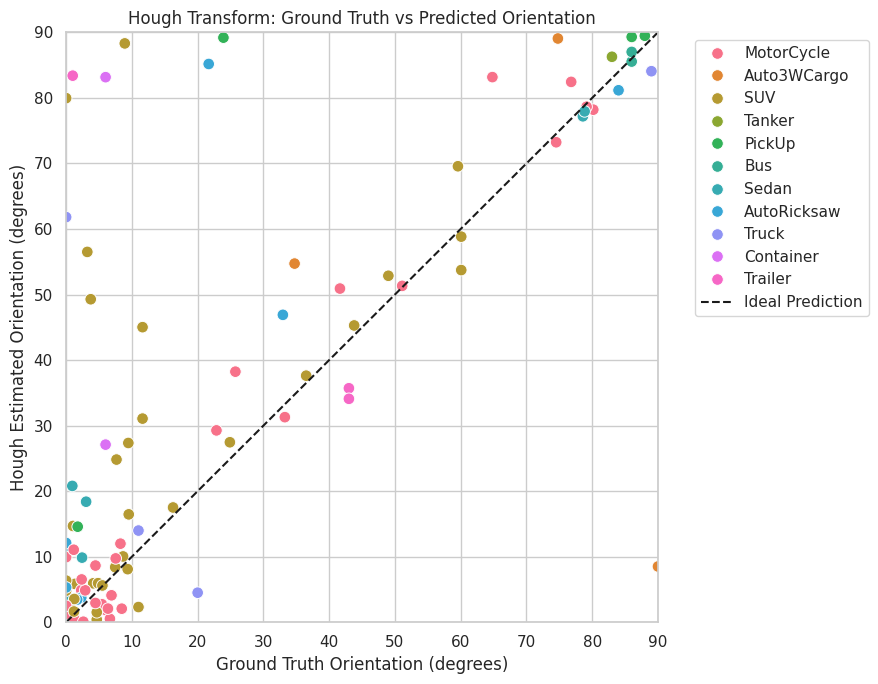

In [6]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=valid_df,
    x="Ground_Truth_Orientation_deg",
    y="Hough_Estimated_Orientation_deg",
    hue="Vehicle_Class",
    s=70
)

plt.plot(
    [0, 90],
    [0, 90],
    "k--",
    label="Ideal Prediction"
)

plt.xlim(0, 90)
plt.ylim(0, 90)

plt.xlabel("Ground Truth Orientation (degrees)")
plt.ylabel("Hough Estimated Orientation (degrees)")

plt.title(
    "Hough Transform: Ground Truth vs Predicted Orientation"
)

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPHS_DIR,
        "03_hough_gt_vs_prediction.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Relationship Between Vehicle Orientation and Error

This analysis investigates whether the performance of the Hough
Transform changes with the ground-truth orientation of the vehicle.

The relationship is examined using a scatter plot of angular error
against vehicle orientation.

The orientations are also divided into six ranges to compare
the average errors at different angles.

This helps investigate whether particular vehicle orientations
are associated with greater estimation difficulty.

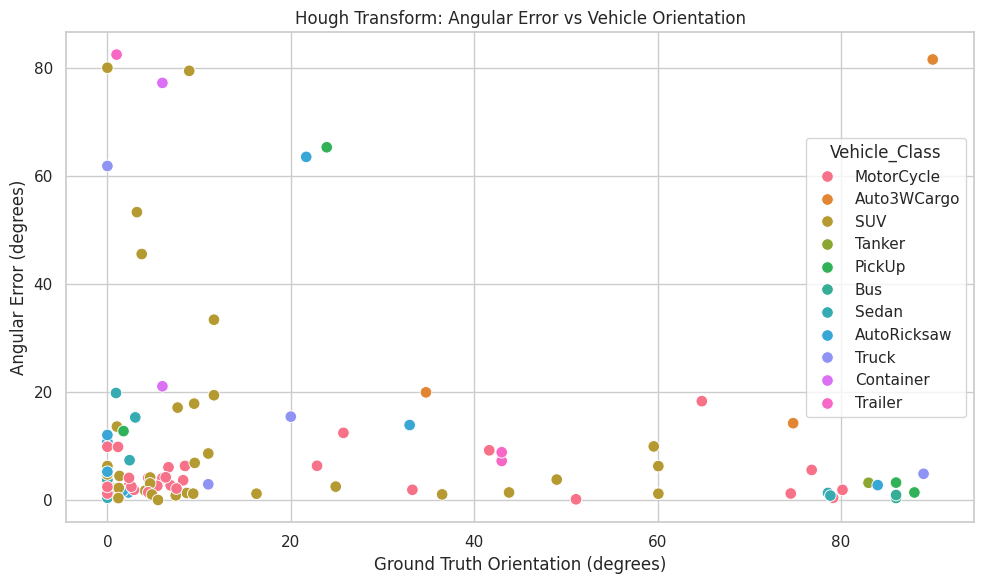

In [7]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=valid_df,
    x="Ground_Truth_Orientation_deg",
    y="Hough_Angular_Error_deg",
    hue="Vehicle_Class",
    s=70
)

plt.xlabel("Ground Truth Orientation (degrees)")
plt.ylabel("Angular Error (degrees)")

plt.title(
    "Hough Transform: Angular Error vs Vehicle Orientation"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPHS_DIR,
        "04_hough_error_vs_orientation.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Orientation_Range,Sample_Count,Mean_Error_deg
0,0-15,62,13.320645
1,15-30,7,23.851429
2,30-45,8,7.996250
3,45-60,3,4.690000
4,60-75,5,8.304000
5,75-90,13,8.396923


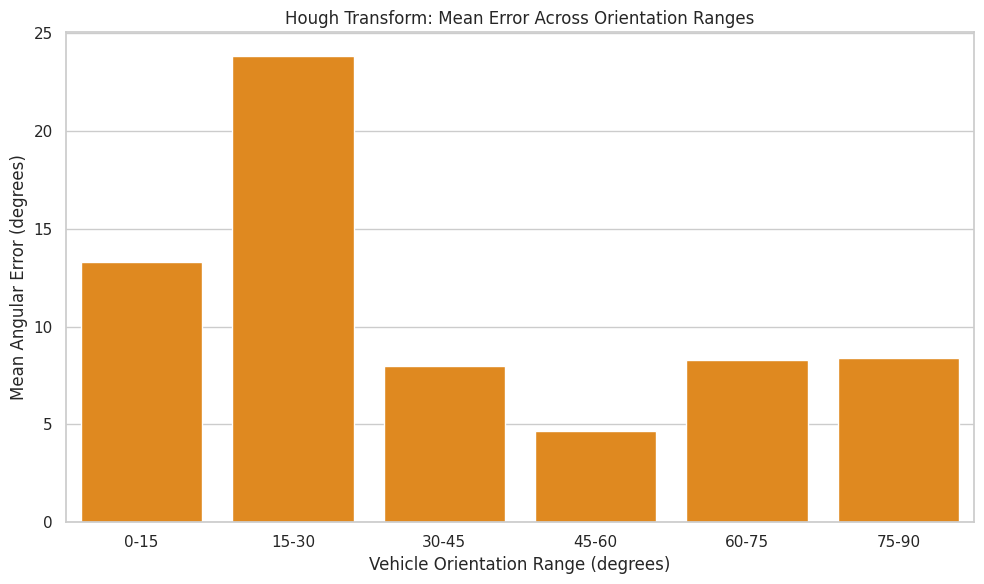

In [8]:
orientation_bins = [0, 15, 30, 45, 60, 75, 90.00001]

orientation_labels = [
    "0-15",
    "15-30",
    "30-45",
    "45-60",
    "60-75",
    "75-90"
]

valid_df["Orientation_Range"] = pd.cut(
    valid_df["Ground_Truth_Orientation_deg"],
    bins=orientation_bins,
    labels=orientation_labels,
    include_lowest=True,
    right=False
)

orientation_stats = valid_df.groupby(
    "Orientation_Range",
    observed=False
).agg(
    Sample_Count=("Hough_Angular_Error_deg", "count"),
    Mean_Error_deg=("Hough_Angular_Error_deg", "mean")
).reset_index()

orientation_stats.to_csv(
    os.path.join(
        TABLES_DIR,
        "02_hough_orientationwise_error.csv"
    ),
    index=False
)

display(orientation_stats)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=orientation_stats,
    x="Orientation_Range",
    y="Mean_Error_deg",
    color="darkorange"
)

plt.xlabel("Vehicle Orientation Range (degrees)")
plt.ylabel("Mean Angular Error (degrees)")

plt.title(
    "Hough Transform: Mean Error Across Orientation Ranges"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPHS_DIR,
        "05_hough_orientationwise_mean_error.png"
    ),
    dpi=300
)

plt.show()

## 5. Identification of High-Error Samples

To investigate the reasons behind the high angular error,
individual vehicle samples are ranked according to their
Hough Transform prediction error.

The samples with the largest angular errors are identified
for further examination.

These samples are particularly useful for investigating cases
where the detected image lines may not correspond to the actual
longitudinal axis of the vehicle.

In [9]:
worst_predictions = valid_df.sort_values(
    "Hough_Angular_Error_deg",
    ascending=False
)

selected_columns = [
    "Vehicle_ID",
    "Vehicle_Class",
    "Ground_Truth_Orientation_deg",
    "Hough_Estimated_Orientation_deg",
    "Hough_Angular_Error_deg"
]

if "Image_ID" in worst_predictions.columns:
    selected_columns.insert(1, "Image_ID")

worst_predictions[selected_columns].to_csv(
    os.path.join(
        TABLES_DIR,
        "03_hough_worst_predictions.csv"
    ),
    index=False
)

print("TOP 15 HIGHEST-ERROR SAMPLES")

display(
    worst_predictions[selected_columns].head(15)
)

TOP 15 HIGHEST-ERROR SAMPLES


,Vehicle_ID,Image_ID,Vehicle_Class,Ground_Truth_Orientation_deg,Hough_Estimated_Orientation_deg,Hough_Angular_Error_deg
84,cLEH_vQvJ_zAUO_vehicle_1,cLEH_vQvJ_zAUO,Trailer,1.00,83.39,82.39
72,hwun_OlDq_ey5G_vehicle_1,hwun_OlDq_ey5G,Auto3WCargo,90.00,8.51,81.49
19,dH2R_2Thg_72eh_vehicle_1,dH2R_2Thg_72eh,SUV,0.00,79.96,79.96
74,wmtT_f6a4_vb0t_vehicle_1,wmtT_f6a4_vb0t,SUV,8.92,88.31,79.39
49,y0bo_oHBY_y2mz_vehicle_1,y0bo_oHBY_y2mz,Container,6.00,83.16,77.16
16,RXzz_utpH_j6LU_vehicle_1,RXzz_utpH_j6LU,PickUp,23.92,89.19,65.27
38,jlWW_Ztu4_0drW_vehicle_1,jlWW_Ztu4_0drW,AutoRicksaw,21.68,85.17,63.49
52,GgeL_lRkt_HpI7_vehicle_1,GgeL_lRkt_HpI7,Truck,0.00,61.81,61.81
61,ZKIx_Msfo_O7V9_vehicle_1,ZKIx_Msfo_O7V9,SUV,3.22,56.50,53.28
11,ON14_goh0_iF0V_vehicle_1,ON14_goh0_iF0V,SUV,3.74,49.28,45.54


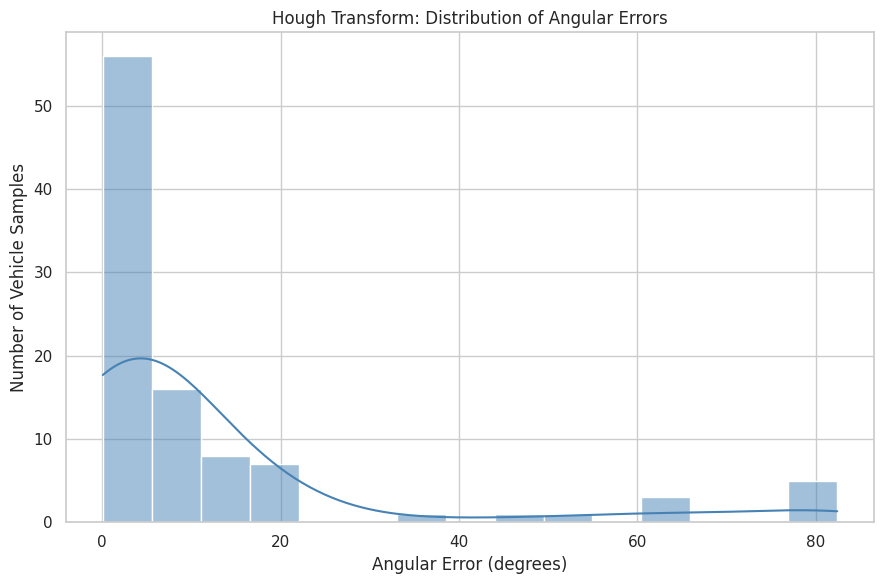

In [10]:
plt.figure(figsize=(9, 6))

sns.histplot(
    valid_df["Hough_Angular_Error_deg"],
    bins=15,
    kde=True,
    color="steelblue"
)

plt.xlabel("Angular Error (degrees)")
plt.ylabel("Number of Vehicle Samples")

plt.title(
    "Hough Transform: Distribution of Angular Errors"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPHS_DIR,
        "06_hough_error_distribution.png"
    ),
    dpi=300
)

plt.show()

## 6. Investigation of Possible Error Sources

The Hough Transform estimates orientation using prominent line
segments detected from image edges.

However, the detected lines may not always represent the actual
longitudinal axis of the vehicle.

The following possible sources of error are considered:

### 1. Multiple Strong Edges

Vehicles contain several visible edges, including roof boundaries,
windows, and structural features. The Hough Transform may detect
these lines instead of the main vehicle axis.

### 2. Background Interference

Road markings, shadows, and background objects within the cropped
region may introduce additional line segments that affect orientation
estimation.

### 3. Vehicle Shape and Geometry

Different vehicle classes have different structures and edge
distributions. These differences may influence which lines are
detected and how their orientations are combined.

### 4. Fragmented or Weak Edges

Blur, low contrast, and partially visible vehicle boundaries may
produce short or disconnected lines, leading to unstable estimates.

### 5. Incorrect Dominant Direction

The detected line segments may represent the vehicle's width,
diagonal features, or other structures rather than its longitudinal
direction.

These explanations are treated as possible causes. Visual inspection
of the highest-error samples is required to determine which factors
actually contribute to the observed errors.

In [11]:
mean_error = valid_df["Hough_Angular_Error_deg"].mean()
median_error = valid_df["Hough_Angular_Error_deg"].median()
max_error = valid_df["Hough_Angular_Error_deg"].max()

worst_class_name = worst_class["Vehicle_Class"]
worst_class_error = worst_class["Mean_Error_deg"]
worst_class_count = int(worst_class["Sample_Count"])

total_samples = len(df)
valid_samples = len(valid_df)
missing_samples = total_samples - valid_samples

summary = f"""
WEEK 5: HOUGH TRANSFORM ERROR ANALYSIS
=====================================

Objective:
Investigate the high angular error observed for the
Hough Transform during previous experiments.

Dataset:
Total evaluated vehicles: {total_samples}
Valid Hough predictions: {valid_samples}
Missing/failed predictions: {missing_samples}

Overall Hough Performance:
Mean angular error: {mean_error:.2f} degrees
Median angular error: {median_error:.2f} degrees
Maximum angular error: {max_error:.2f} degrees

Class-Wise Analysis:
Highest mean-error class: {worst_class_name}
Mean angular error: {worst_class_error:.2f} degrees
Number of samples: {worst_class_count}

Analysis Performed:
1. Class-wise mean angular error comparison.
2. Class-wise error distribution analysis.
3. Ground truth vs Hough prediction analysis.
4. Error vs vehicle orientation analysis.
5. Orientation-range-wise mean error comparison.
6. Identification of individual high-error predictions.
7. Investigation of possible sources of Hough error.

Interpretation:
The analysis identifies the classes, orientations, and
individual samples associated with larger Hough errors.

The results alone do not confirm the physical causes
of these errors. Further visual examination of the
detected Hough lines is required before attributing
the errors to vehicle geometry or background effects.

Next Step:
Inspect the Hough line detections for the highest-error
vehicle samples and investigate the reasons for
incorrect dominant-line orientation.
"""

print(summary)

summary_path = os.path.join(
    WEEK5_DIR,
    "Week5_Hough_Analysis_Summary.txt"
)

with open(summary_path, "w") as f:
    f.write(summary)

print("\nSummary saved to:", summary_path)


WEEK 5: HOUGH TRANSFORM ERROR ANALYSIS

Objective:
Investigate the high angular error observed for the
Hough Transform during previous experiments.

Dataset:
Total evaluated vehicles: 100
Valid Hough predictions: 98
Missing/failed predictions: 2

Overall Hough Performance:
Mean angular error: 12.46 degrees
Median angular error: 4.18 degrees
Maximum angular error: 82.39 degrees

Class-Wise Analysis:
Highest mean-error class: Container
Mean angular error: 49.13 degrees
Number of samples: 2

Analysis Performed:
1. Class-wise mean angular error comparison.
2. Class-wise error distribution analysis.
3. Ground truth vs Hough prediction analysis.
4. Error vs vehicle orientation analysis.
5. Orientation-range-wise mean error comparison.
6. Identification of individual high-error predictions.
7. Investigation of possible sources of Hough error.

Interpretation:
The analysis identifies the classes, orientations, and
individual samples associated with larger Hough errors.

The results alone do n